# 04 — Read the evidence and its limits

This notebook consumes the saved pilot collection. It does not rerun or tune optimisers. Each plot/table is generated from recorded run IDs; curated outputs are written under `results/` with a provenance index.

Primary analysis: paired changes in log loss under rotation, conditional on a fixed measured objective. Secondary analysis: boundary handling, predictive assessment, internal diagnostics and time. Keep single-seed demonstrations separate from the three-seed primary pilot.

In [1]:
from pathlib import Path
import os, json, sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/bo_vs_es").exists())
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / "artifacts/.matplotlib"))
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from bo_vs_es.analysis.study import save_figure
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 15)
print("Repository:", ROOT)
print("Python:", sys.version.split()[0])


Repository: /Users/mihirsinha/Downloads/repo/Dsa4212-final-project-bayesian-vs-evolutionary
Python: 3.13.6


/Users/mihirsinha/Downloads/repo/Dsa4212-final-project-bayesian-vs-evolutionary/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
from bo_vs_es.analysis.study import (load_results, plot_convergence, paired_rotation_effects,
    effect_summary, plot_assessment, boundary_table, export_results, diagnostic_figure)
from bo_vs_es.experiments.runner import jobs_for
results=load_results()
display(results.groupby(["block","status"]).size().rename("runs").reset_index())
assert results.status.eq("complete").all(), "Investigate failures; do not silently drop them"
print("All complete-run hashes, evaluation counts and summaries verified.")
from bo_vs_es.analysis.study import validate_collection
display(validate_collection(results))
from bo_vs_es.analysis.study import COLORS

,block,status,runs
0,battery_ball,complete,30
1,battery_boundary,complete,14
2,ocv_sensitivity,complete,10
3,quadratic_control,complete,30


All complete-run hashes, evaluation counts and summaries verified.


{'verified_runs': 84,
 'search_calls': 8400,
 'assessment_calls': 108,
 'additional_simulator_calls': 0,
 'matched_initial_designs': 4}

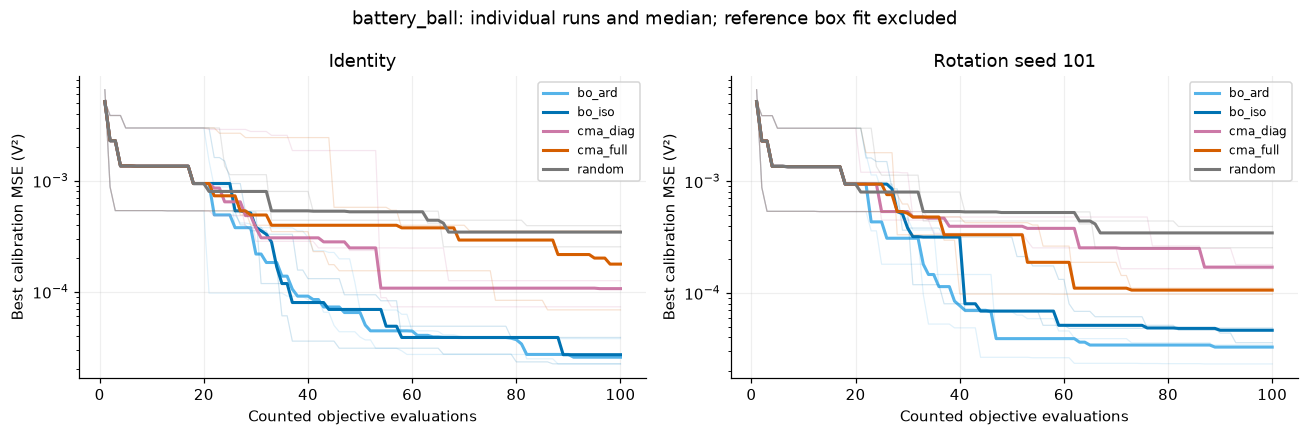

,method,seed,domain,handler,rotation_seed,log10_loss_ratio,run_id,run_id_identity
0,bo_iso,0,ball,none,101.0,3.351205e-01,fc35d0690cbcabe3,8dbda071f08c63de
1,bo_ard,0,ball,none,101.0,-4.420587e-02,aadc3c141350e396,18ffa7aef4b67cce
2,cma_full,0,ball,resample,101.0,-2.236290e-01,1ba4c9f98de22830,7a05895a5b9b8872
3,cma_diag,0,ball,resample,101.0,2.027264e-01,146f7ccf87fdb508,84cd1379250dff71
4,random,0,ball,none,101.0,-3.375146e-16,4c8f2838041d7cfa,7c69a4947014b885
5,bo_iso,1,ball,none,101.0,7.730213e-02,557515913934472d,e04ed0555fab7264
6,bo_ard,1,ball,none,101.0,-4.611731e-02,eedcbb6d3c5c95aa,e7a4430775f6aefe
7,cma_full,1,ball,resample,101.0,2.058933e-01,e67c132c40cf6df4,3d574436965297c0
8,cma_diag,1,ball,resample,101.0,3.519165e-01,4f2769990de799ec,ebf696dd77e4986e
9,random,1,ball,none,101.0,1.639357e-15,1de4d01fb9820aa8,6020a64e99250251


,method,seeds,mean_log10_ratio,mean_absolute_log10_ratio,bootstrap_low,bootstrap_high,interpretation
0,bo_ard,3,2.490995e-02,8.512540e-02,-4.611731e-02,1.650530e-01,descriptive only: fewer than 10 seeds
1,bo_iso,3,1.779245e-01,1.779245e-01,7.730213e-02,3.351205e-01,descriptive only: fewer than 10 seeds
2,cma_diag,3,2.363847e-01,2.363847e-01,1.545110e-01,3.519165e-01,descriptive only: fewer than 10 seeds
3,cma_full,3,-1.928845e-01,3.301467e-01,-5.609177e-01,2.058933e-01,descriptive only: fewer than 10 seeds
4,random,3,4.339474e-16,6.589571e-16,-3.375146e-16,1.639357e-15,descriptive only: fewer than 10 seeds


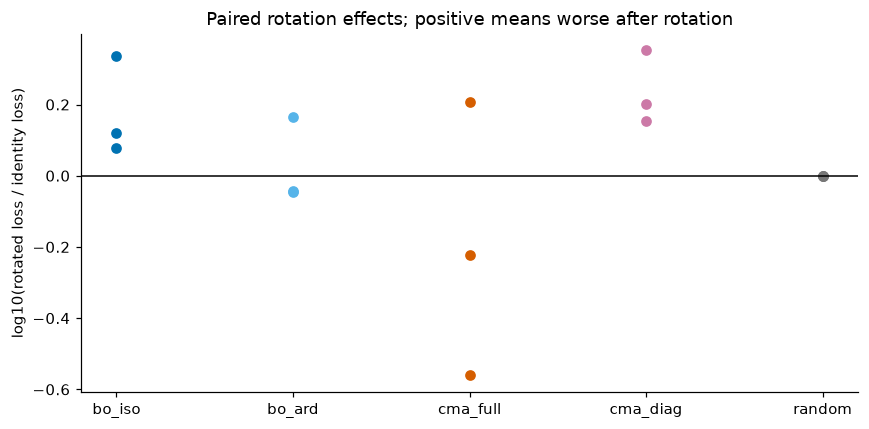

,contrast,seeds,mean_absolute_effect_difference,bootstrap_low,bootstrap_high,interpretation
0,bo_ard minus bo_iso,3,-0.092799,-0.290915,0.043702,descriptive pilot contrast
1,cma_diag minus cma_full,3,-0.093762,-0.406407,0.146023,descriptive pilot contrast


In [3]:
fig=plot_convergence(results); save_figure(fig,"pilot_convergence"); plt.show()
pairs=paired_rotation_effects(results)
display(pairs)
effects=effect_summary(pairs)
display(effects)
fig,ax=plt.subplots(figsize=(8,4))
for i,(method,group) in enumerate(pairs.groupby("method",sort=False)):
    ax.scatter(np.full(len(group),i),group.log10_loss_ratio,label=method,color=COLORS[method])
ax.axhline(0,color="black",lw=1)
ax.set(xticks=range(pairs.method.nunique()),xticklabels=pairs.method.unique(),
       ylabel="log10(rotated loss / identity loss)",title="Paired rotation effects; positive means worse after rotation")
fig.tight_layout(); save_figure(fig,"pilot_rotation_effects"); plt.show()
from bo_vs_es.analysis.study import sensitivity_contrasts
contrasts=sensitivity_contrasts(pairs)
display(contrasts)
contrasts.to_csv(ROOT/"results/tables/pilot_sensitivity_contrasts.csv",index=False)

**Uncertainty:** the displayed bootstrap resamples optimiser seeds after averaging selected rotations within each seed. With only three seeds, the interval is descriptive and unstable. It does not quantify uncertainty across cells or all possible rotations. No hypothesis-test significance claims are made.

Individual trajectory points are not independent replications. An invariant optimiser can be consistently poor, and orientation sensitivity does not imply that a rotation must make the loss worse.

Signed effects show whether a selected orientation improves or worsens loss. Absolute log-ratios measure sensitivity without cancellation. The paired contrasts subtract isotropic/full-CMA absolute effects from ARD/diagonal effects within each seed, then resample seeds. A negative contrast contradicts the proposed direction on these runs; it does not prove universal reverse ordering.

For CMA, equal integer seeds do not couple the physical Gaussian draws pathwise. Absolute paired changes therefore include ordinary sampling variation even if the algorithm is invariant in distribution. Use signed mean contrasts and repeated-run uncertainty before asserting systematic orientation bias; do not interpret the absolute contrast as a pure causal measure of rotation dependence.

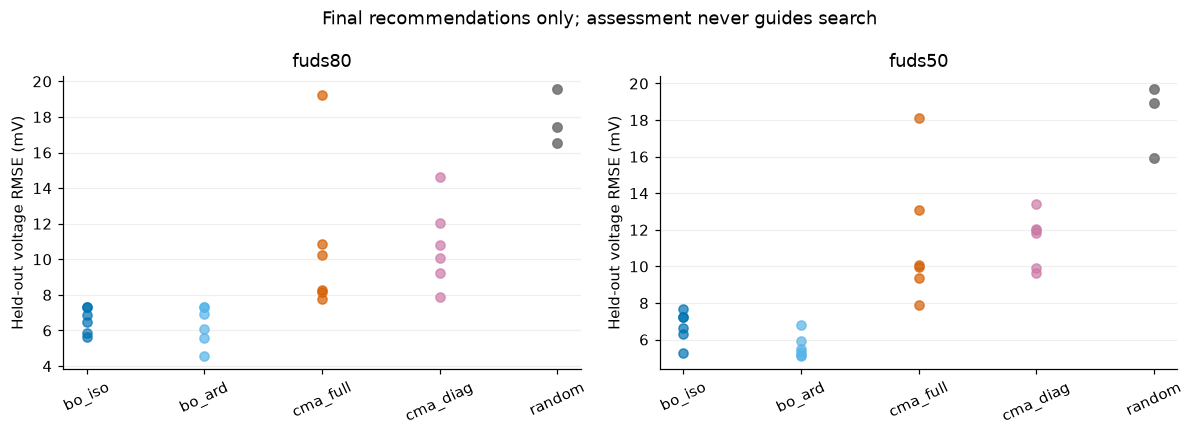

,best_loss,fuds80_rmse_v,fuds50_rmse_v,search_s,objective_s,decision_and_logging_s
method,,,,,,
bo_ard,0.000029,0.006508,0.005394,31.587524,0.136911,31.450173
bo_iso,0.000037,0.006664,0.006917,22.154883,0.138615,22.016470
cma_diag,0.000145,0.010412,0.011911,0.157040,0.136533,0.020507
cma_full,0.000108,0.009271,0.010017,0.158363,0.136453,0.022335
random,0.000344,0.017413,0.018918,0.148387,0.135395,0.012183


In [4]:
fig=plot_assessment(results); save_figure(fig,"pilot_heldout"); plt.show()
display(results[results.block=="battery_ball"].groupby("method")[["best_loss","fuds80_rmse_v","fuds50_rmse_v","search_s","objective_s","decision_and_logging_s"]].median())

## Boundary mechanism check
Compare resampling and projection only on the same box domain. Both mappings preserve the physical feasible set. A ball-versus-box difference also changes the optimisation problem and cannot isolate a boundary-handler effect.

The interaction below is `(rotation effect under projection) − (rotation effect under resampling)`, expressed as log10 loss ratios. One pilot seed cannot establish a reproducible interaction.

,run_id,method,seed,rotation_seed,handler,best_loss,rejected_fraction,repaired_fraction,search_s
30,73096dea4da538b6,bo_iso,0,NaN,none,0.000121,0.000000,0.0000,14.088502
31,3281134a69830ec3,bo_ard,0,NaN,none,0.000166,0.000000,0.0000,14.133392
32,f3665ae77b12d2e4,cma_full,0,NaN,resample,0.000306,0.130435,0.0000,0.154586
33,d1c2f5f6b99d6236,cma_full,0,NaN,project,0.000072,0.000000,0.1625,0.152905
34,17bfb0df37d93c1d,cma_diag,0,NaN,resample,0.000081,0.036145,0.0000,0.153427
35,0bb4a358a035f823,cma_diag,0,NaN,project,0.000141,0.000000,0.1000,0.153000
36,8ab8cdfc29c9111e,random,0,NaN,none,0.000279,0.000000,0.0000,0.143794
37,d5961f4839b096ea,bo_iso,0,101.0,none,0.000121,0.000000,0.0000,13.861387
38,0b91705d864d8b4e,bo_ard,0,101.0,none,0.000416,0.000000,0.0000,14.109126
39,8441a4ee25960585,cma_full,0,101.0,resample,0.000146,0.069767,0.0000,0.160549


,,handler,project,resample,projection_minus_resampling
method,seed,orientation,,,
cma_diag,0,101.0,0.502793,0.071377,0.431416
cma_full,0,101.0,0.359728,-0.320668,0.680396


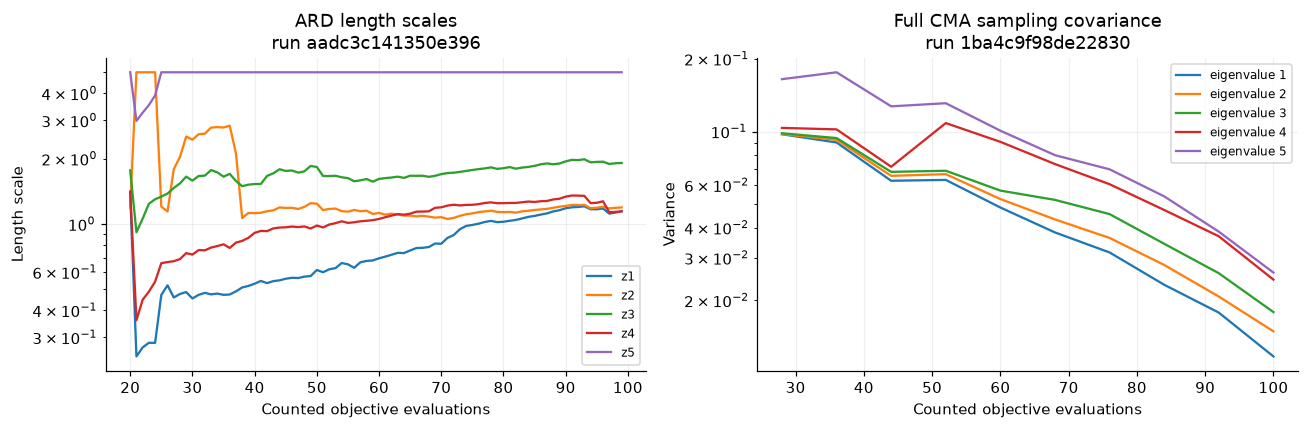

In [5]:
boundary=boundary_table(results)
display(boundary)
from bo_vs_es.analysis.study import boundary_interaction
interaction=boundary_interaction(results)
display(interaction)
interaction.to_csv(ROOT/"results/tables/pilot_boundary_interaction.csv")
fig=diagnostic_figure(results); save_figure(fig,"pilot_internal_diagnostics"); plt.show()

## Controlled conditioning and assessment of model assumptions
The following results change the condition number on a known quadratic. They do not assign a global condition number to the battery loss. Natural battery parameter directions may already be coupled, while isotropic quadratic geometry is a useful control.

Review the model-reference residuals in notebook 02 alongside these optimisation results. Better calibration loss need not give a better held-out prediction when the model or transferred OCV curve is imperfect.

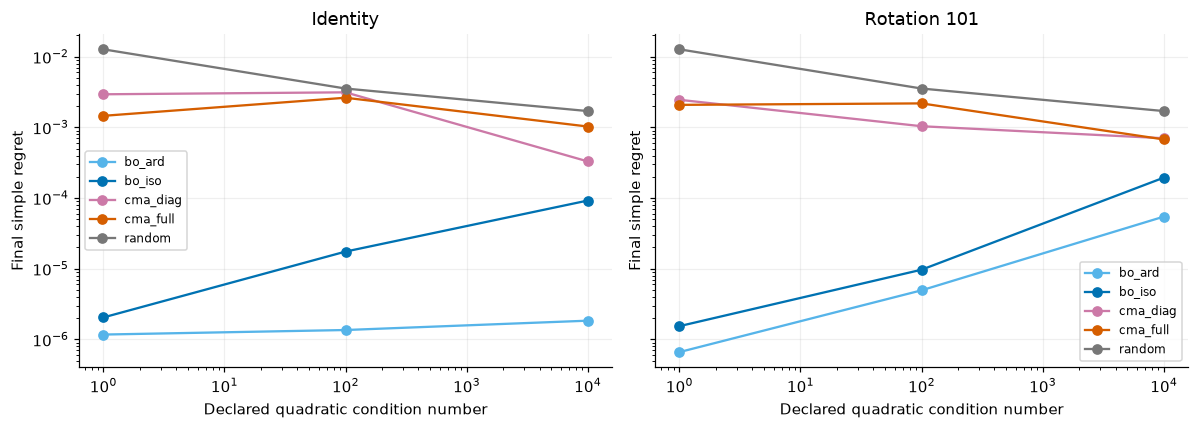

In [6]:
q=results[results.block=="quadratic_control"].copy()
fig,axes=plt.subplots(1,2,figsize=(11,4),sharey=True)
for ax,rot in zip(axes,[None,101]):
    subset=q[q.rotation_seed.isna() if rot is None else q.rotation_seed.eq(rot)]
    for method,group in subset.groupby("method"):
        group=group.sort_values("condition")
        ax.plot(group.condition,group.best_loss,"o-",label=method,color=COLORS[method])
    ax.set(xscale="log",yscale="log",xlabel="Declared quadratic condition number",ylabel="Final simple regret",
           title="Identity" if rot is None else "Rotation 101")
    ax.legend(fontsize=8); ax.grid(alpha=.2)
fig.tight_layout(); save_figure(fig,"pilot_quadratic_controls"); plt.show()
export_results(results)

## Numerical and identifiability diagnostics
A completed run means its budget and records are valid, not that every GP fit reached a stationary point. Inspect warnings and length-scale bounds before attributing a result to kernel geometry. The table below uses the current collection's exact run IDs.

For physical interpretation we sort the two RC branches by time constant **only here**. A ratio near one suggests poorly separated timescales; it is not a formal identifiability test. Near-zero boundary margins show where the imposed domain may constrain a recommendation. These diagnostics complement the local Jacobian in notebook 02.

In [7]:
from bo_vs_es.analysis.study import optimiser_health, recommendation_parameters
health=optimiser_health(results)
display(health.groupby(["method","fit_status"]).size().rename("GP fits").reset_index())
print("Steps with numerical warnings:", int(health.warning_count.gt(0).sum()), "of",len(health))
display(health[health.warning_count.gt(0)].head(8))
health.to_csv(ROOT/"results/tables/pilot_optimiser_health.csv",index=False)
parameters=recommendation_parameters(results)
display(parameters[parameters.block=="battery_ball"])
parameters.to_csv(ROOT/"results/tables/pilot_recommendation_parameters.csv",index=False)
print("All diagnostics above refer to the source run_id column, not extra optimisation runs.")

,method,fit_status,GP fits
0,bo_ard,OptimizationStatus.STOPPED,8
1,bo_ard,OptimizationStatus.SUCCESS,1272
2,bo_iso,OptimizationStatus.SUCCESS,1280


Steps with numerical warnings: 0 of 2560


,run_id,block,method,seed,rotation_seed,after_evaluations,fit_status,fit_message,warning_count,warnings,lengthscale_min,lengthscale_max


,run_id,block,method,seed,rotation_seed,R0_ohm,R_fast_ohm,tau_fast_s,R_slow_ohm,tau_slow_s,tau_ratio,dimensionless_boundary_margin
0,8dbda071f08c63de,battery_ball,bo_iso,0,NaN,0.074883,0.010666,22.160645,0.041522,218.178363,9.845307,0.000000e+00
1,18ffa7aef4b67cce,battery_ball,bo_ard,0,NaN,0.076480,0.001332,28.377099,0.047469,141.485791,4.985915,0.000000e+00
2,7a05895a5b9b8872,battery_ball,cma_full,0,NaN,0.069492,0.002616,23.123741,0.042013,28.431956,1.229557,1.208999e-01
3,84cd1379250dff71,battery_ball,cma_diag,0,NaN,0.074272,0.003571,15.913006,0.032442,62.680358,3.938939,1.344599e-01
4,7c69a4947014b885,battery_ball,random,0,NaN,0.088129,0.006271,41.854232,0.002948,130.302644,3.113249,2.407852e-01
5,e04ed0555fab7264,battery_ball,bo_iso,1,NaN,0.077663,0.001822,14.854418,0.043935,135.696950,9.135124,0.000000e+00
6,e7a4430775f6aefe,battery_ball,bo_ard,1,NaN,0.075925,0.007180,23.715940,0.045762,223.998016,9.445040,0.000000e+00
7,3d574436965297c0,battery_ball,cma_full,1,NaN,0.079359,0.004619,41.955401,0.032763,121.398268,2.893508,1.237062e-01
8,ebf696dd77e4986e,battery_ball,cma_diag,1,NaN,0.083175,0.002923,81.548483,0.045377,174.797668,2.143482,7.422683e-03
9,6020a64e99250251,battery_ball,random,1,NaN,0.089896,0.004678,27.562810,0.017304,113.746853,4.126823,1.688229e-01


All diagnostics above refer to the source run_id column, not extra optimisation runs.


## Follow-up: does an invariant kernel give an invariant numerical search?
Compare mapped physical-log candidates at the same evaluation index. The first 20 observations are matched. Random search should stay matched throughout; CMA need not have identical trajectories under the same integer seed. For isotropic BO, tiny candidate deviations can accumulate through subsequent refitting and acquisition optimisation. This plot diagnoses when paths depart; it does not by itself identify a unique solver mechanism.

The frozen-history control below compares GP posterior moments and LogEI on 100 matched query points, using the same 20 initial observations and fixed scalar hyperparameters. It makes no additional simulator calls and isolates GP mathematics from hyperparameter fitting and acquisition maximisation.

source_run_id                                                         8dbda071f08c63de
initial_observations                                                                20
query_points                                                                       100
max_posterior_mean_difference                                                      0.0
max_posterior_variance_difference                                                  0.0
max_log_ei_difference                                                              0.0
extra_simulator_calls                                                                0
scope                                fixed scalar length scale .7, output scale 1 a...
dtype: object

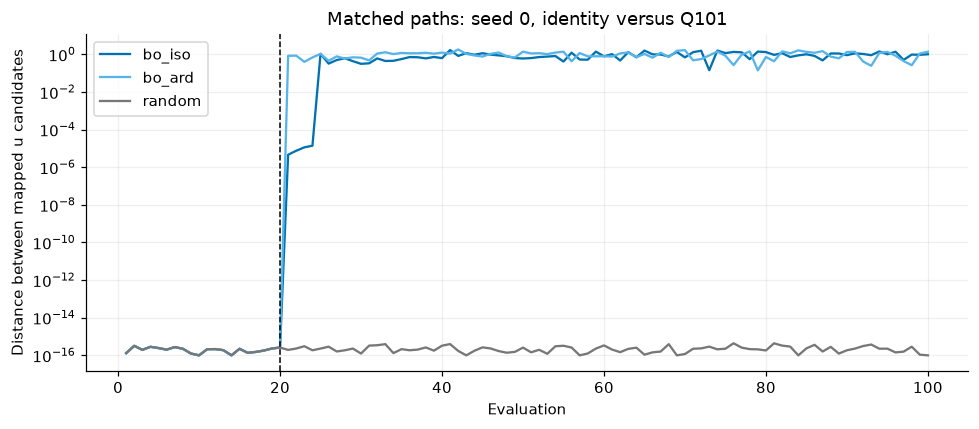

,method,seed,rotation_seed,run_id,run_id_identity,evaluation,base_coordinate_distance
320,bo_iso,0,101.0,fc35d0690cbcabe3,8dbda071f08c63de,21,4.615749e-06
321,bo_iso,0,101.0,fc35d0690cbcabe3,8dbda071f08c63de,22,7.532284e-06
322,bo_iso,0,101.0,fc35d0690cbcabe3,8dbda071f08c63de,23,1.142045e-05
323,bo_iso,0,101.0,fc35d0690cbcabe3,8dbda071f08c63de,24,1.391385e-05
324,bo_iso,0,101.0,fc35d0690cbcabe3,8dbda071f08c63de,25,1.075850e+00
420,bo_iso,1,101.0,557515913934472d,e04ed0555fab7264,21,1.473820e-06
421,bo_iso,1,101.0,557515913934472d,e04ed0555fab7264,22,1.236289e-06
422,bo_iso,1,101.0,557515913934472d,e04ed0555fab7264,23,4.830946e-07
423,bo_iso,1,101.0,557515913934472d,e04ed0555fab7264,24,2.561076e-06
424,bo_iso,1,101.0,557515913934472d,e04ed0555fab7264,25,1.854646e-06


In [8]:
from bo_vs_es.analysis.study import paired_path_deviations, frozen_gp_rotation_check
paths=paired_path_deviations(results)
paths.to_csv(ROOT/"results/tables/pilot_path_deviations.csv",index=False)
control=frozen_gp_rotation_check(results)
display(pd.Series(control))
(ROOT/"results/tables/frozen_gp_rotation_control.json").write_text(json.dumps(control,indent=2))
fig,ax=plt.subplots(figsize=(9,4))
for method in ["bo_iso","bo_ard","random"]:
    subset=paths[(paths.method==method)&(paths.seed==0)]
    ax.semilogy(subset.evaluation,np.maximum(subset.base_coordinate_distance,1e-16),label=method,color=COLORS[method])
ax.axvline(20,color="black",ls="--",lw=1)
ax.set(xlabel="Evaluation",ylabel="Distance between mapped u candidates",title="Matched paths: seed 0, identity versus Q101")
ax.legend();ax.grid(alpha=.2);fig.tight_layout()
save_figure(fig,"pilot_path_divergence");plt.show()
display(paths[(paths.method=="bo_iso")&paths.evaluation.between(21,25)])

## What the main study would cost
The main recipe contains 20 seeds, identity plus three rotations, 300 evaluations per run, and the same declared method settings. Nothing in this notebook launches it. The estimate below extrapolates observed method-specific pilot time linearly in search evaluations; it can understate GP cost as training sets grow and excludes downloading, notebook rendering and reference fits. Treat it as a planning estimate, not a measured main-study runtime.

In [9]:
main_recipe=json.loads((ROOT/"configs/experiments/main.json").read_text())
main_jobs=pd.DataFrame(jobs_for(main_recipe))
pilot_seconds_per_call=results.groupby("method").apply(lambda g:g.search_s.sum()/g.evaluations.sum(),include_groups=False)
estimated_seconds=sum(row.budget*pilot_seconds_per_call[row.method] for row in main_jobs.itertuples())
print("Main runs:",len(main_jobs),"; maximum search calls:",int(main_jobs.budget.sum()))
print(f"Linear extrapolation from pilot: {estimated_seconds/3600:.2f} CPU wall-clock hours (GP scaling may increase this).")
print("NOT executed: .venv/bin/python scripts/run_experiments.py --config configs/experiments/main.json")
display(main_jobs.groupby(["block","objective"]).size().rename("configured_runs").reset_index())
print("Curated outputs: results/figures/ and results/tables/")

Main runs: 2360 ; maximum search calls: 708000
Linear extrapolation from pilot: 19.88 CPU wall-clock hours (GP scaling may increase this).
NOT executed: .venv/bin/python scripts/run_experiments.py --config configs/experiments/main.json


,block,objective,configured_runs
0,battery_ball,battery,400
1,battery_boundary,battery,560
2,ocv_sensitivity,battery,200
3,quadratic_control,quadratic,1200


Curated outputs: reports/figures/ and reports/tables/


## Pilot conclusions

The group found positive signed rotation effects for scalar BO and diagonal CMA in all three primary pilot designs. ARD's effects changed sign, and full CMA's effects varied substantially. The paired absolute-effect contrasts did not establish the predicted ARD-over-scalar or diagonal-over-full sensitivity ordering. Three designs support exploratory observations, not stable population-level inference.

The scalar GP's frozen-history posterior and LogEI agreed under rotation, but sequential physical candidates diverged after the matched initial observations. This separates kernel symmetry from implemented search behaviour and motivated the later fitting/acquisition diagnostics. The pilot alone does not identify a unique numerical cause. Random search remained matched to floating-point precision.

Full CMA had lower median calibration and held-out errors than diagonal CMA at 100 calls, but its signed rotation effects varied across designs. The pilot cannot determine whether covariance adaptation had insufficient time or isolate covariance learning from sampling variation. Longer budgets and same-orientation replication were therefore needed.

In the one-design same-box control, projection-minus-resampling rotation interactions were +0.680 for full CMA and +0.431 for diagonal CMA. Projection increased the signed rotation effect in these particular runs; a single design cannot establish a reproducible handler effect or a fraction of sensitivity attributable to boundaries.

The descriptive calibration and held-out median rankings agreed: ARD BO, scalar BO, full CMA, diagonal CMA, then random search. BO's lower errors came with substantially greater decision time. The two-RC reference improved calibration and FUDS80 errors relative to one RC, supporting the model choice without making either fit a black-box competitor or a certified optimum. The OCV sensitivity comparison changes the objective approximation, so it tests dependence on a modelling assumption rather than optimiser rotation invariance.

**Scope and limits:** this notebook contains the 84-run, 100-call pilot. The original 2,360-run main recipe remained unexecuted; later V2–V5 studies are separate evidence, documented in notebooks 05–06 and the report. One dynamic cell, transferred OCV, fixed capacity/SOC, restricted domains and branch non-identifiability limit physical interpretation. Good prediction does not establish unique parameter recovery.
